# Groupe 1 · Territoire et vulnérabilités
## Peut-on prédire le manque de soins d'une personne au Togo à partir des services présents dans sa zone ?

**Données** : Afrobaromètre, enquête Togo 2024 (1 200 personnes interrogées). Pour chaque personne : la région, le milieu (urbain ou rural), quelques caractéristiques personnelles, les services présents dans sa zone (électricité, eau courante, centre de santé, école, marché…) et la fréquence à laquelle elle a manqué de soins médicaux au cours de l'année.

**Déroulé**
- **Partie A · Explorer les données** (étapes 1 à 9) : statistiques, valeurs manquantes, distributions, valeurs aberrantes, liens entre variables
- **Partie B · Construire les modèles** (étapes 10 à 15)
- **Partie C · Analyser les résultats** (étapes 16 à 23) : erreurs, seuil de décision, surapprentissage, stabilité
- **Partie D · Utiliser et conclure** (étapes 24 à 26)

*Source : Afrobarometer, Togo Round 10 (2024), www.afrobarometer.org.*

# Partie A · Explorer les données

## Étape 1 · Installer et importer les outils

In [1]:
# Installe les trois bibliothèques utilisées dans ce notebook (déjà présentes dans Colab : l'installation est alors immédiate).
# Si le message « you may need to restart the kernel » apparaît, on peut l'ignorer.
%pip install -q pandas scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd                      # pandas : lire et manipuler des tableaux
import matplotlib.pyplot as plt          # matplotlib : dessiner des graphiques
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold   # séparer les données, validation croisée
from sklearn.linear_model import LogisticRegression     # premier modèle : régression logistique
from sklearn.ensemble import RandomForestClassifier     # modèle d'IA : forêt aléatoire
from sklearn.metrics import accuracy_score, recall_score, ConfusionMatrixDisplay   # pour évaluer les modèles

## Étape 2 · Charger les données

In [3]:
import os

# Les fichiers nécessaires : ils doivent être dans le même dossier que ce notebook.
fichiers = ["afrobarometre_togo_2024.csv"]

# Dans Google Colab : si un fichier manque, une fenêtre s'ouvre pour l'envoyer depuis votre ordinateur.
if not all(os.path.exists(f) for f in fichiers):
    from google.colab import files
    files.upload()

donnees = pd.read_csv("afrobarometre_togo_2024.csv")

# Affiche les 5 premières lignes du tableau
donnees.head()

,region,milieu,age,sexe,niveau_instruction,electricite_zone,eau_courante_zone,egouts_zone,reseau_telephone_zone,forage_zone,...,police_zone,centre_sante_zone,marche_zone,banque_zone,transport_zone,menage_radio,menage_television,menage_ordinateur,menage_compte_bancaire,manque_soins
0,Savane,rural,33.0,femme,3.0,1.0,1.0,0.0,1.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,4.0
1,Savane,rural,25.0,femme,4.0,1.0,1.0,0.0,1.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,2.0
2,Maritime,rural,60.0,femme,4.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,1.0,1.0,1.0,1.0,0.0,1.0,2.0
3,Maritime,rural,37.0,femme,2.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,2.0
4,Savane,rural,72.0,homme,0.0,1.0,1.0,0.0,1.0,1.0,...,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,4.0


In [4]:
print("Nombre de personnes :", len(donnees))
print("Nombre de colonnes :", len(donnees.columns))
print()
print("Les colonnes :", list(donnees.columns))

Nombre de personnes : 1200
Nombre de colonnes : 21

Les colonnes : ['region', 'milieu', 'age', 'sexe', 'niveau_instruction', 'electricite_zone', 'eau_courante_zone', 'egouts_zone', 'reseau_telephone_zone', 'forage_zone', 'ecole_zone', 'police_zone', 'centre_sante_zone', 'marche_zone', 'banque_zone', 'transport_zone', 'menage_radio', 'menage_television', 'menage_ordinateur', 'menage_compte_bancaire', 'manque_soins']


**Comment lire les colonnes**
- `manque_soins` : 0 = jamais, 1 = une ou deux fois, 2 = quelques fois, 3 = plusieurs fois, 4 = toujours.
- Colonnes `..._zone` : 1 si le service existe dans la zone de la personne, 0 sinon.
- Colonnes `menage_...` : 1 si le ménage possède l'objet (radio, télévision, ordinateur, compte bancaire).
- `niveau_instruction` : de 0 (aucune instruction) à 9 (post-universitaire) ; 3 = primaire achevé, 5 = secondaire achevé, 8 = université achevée.

## Étape 3 · Statistiques descriptives

`describe()` résume chaque colonne numérique : le nombre de valeurs connues (*count*), la moyenne (*mean*), l'écart-type (*std*, la dispersion autour de la moyenne), le minimum, les quartiles (25 %, 50 % = médiane, 75 %) et le maximum.

In [5]:
donnees.describe().round(2)

,age,niveau_instruction,electricite_zone,eau_courante_zone,egouts_zone,reseau_telephone_zone,forage_zone,ecole_zone,police_zone,centre_sante_zone,marche_zone,banque_zone,transport_zone,menage_radio,menage_television,menage_ordinateur,menage_compte_bancaire,manque_soins
count,1200.00,1193.00,1200.00,1192.00,1192.00,1200.00,1184.00,1192.00,1192.00,1168.00,1176.00,1176.00,1168.00,1198.00,1200.00,1197.00,1186.00,1197.00
mean,35.34,3.74,0.69,0.31,0.03,0.79,0.89,0.81,0.26,0.57,0.54,0.56,0.64,0.78,0.55,0.24,0.39,1.69
std,13.56,2.10,0.46,0.46,0.18,0.41,0.32,0.39,0.44,0.50,0.50,0.50,0.48,0.42,0.50,0.43,0.49,1.20
min,18.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,25.00,2.00,0.00,0.00,0.00,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00
50%,32.00,4.00,1.00,0.00,0.00,1.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,0.00,2.00
75%,43.00,5.00,1.00,1.00,0.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00,1.00,3.00
max,88.00,9.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,4.00


**À regarder** : l'âge va de 18 à 88 ans, avec une médiane de 32 ans. Pour les colonnes 0/1, la moyenne donne directement la part de « oui » : par exemple, la moyenne de `centre_sante_zone` est la part des personnes ayant un centre de santé dans leur zone.

## Étape 4 · Les valeurs manquantes

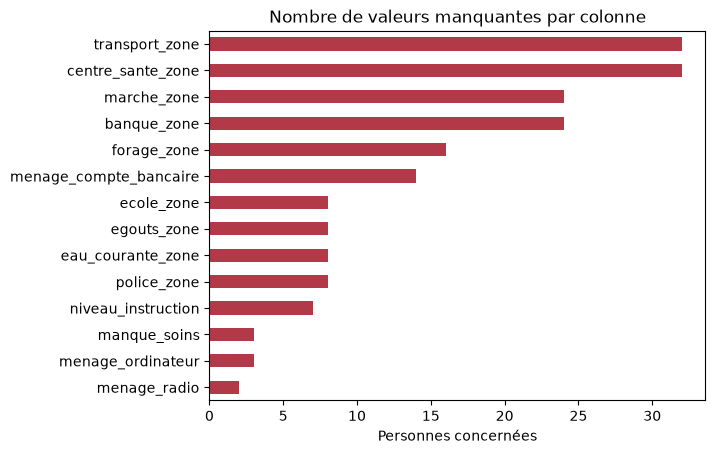

In [6]:
# Nombre de valeurs manquantes dans chaque colonne
manquantes = donnees.isna().sum()
manquantes = manquantes[manquantes > 0].sort_values()

manquantes.plot(kind="barh", color="#B23A48")
plt.title("Nombre de valeurs manquantes par colonne")
plt.xlabel("Personnes concernées")
plt.show()

Peu de valeurs manquent (quelques dizaines au plus sur 1 200). On pourra retirer ces personnes sans perdre beaucoup d'information. Si une colonne avait 40 % de manquants, il faudrait réfléchir autrement.

## Étape 5 · Les distributions

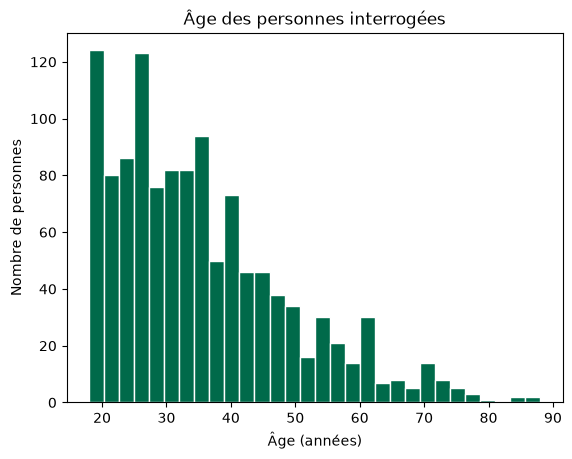

In [7]:
# Histogramme de l'âge : combien de personnes dans chaque tranche d'âge
plt.hist(donnees["age"], bins=30, color="#006A4A", edgecolor="white")
plt.title("Âge des personnes interrogées")
plt.xlabel("Âge (années)")
plt.ylabel("Nombre de personnes")
plt.show()

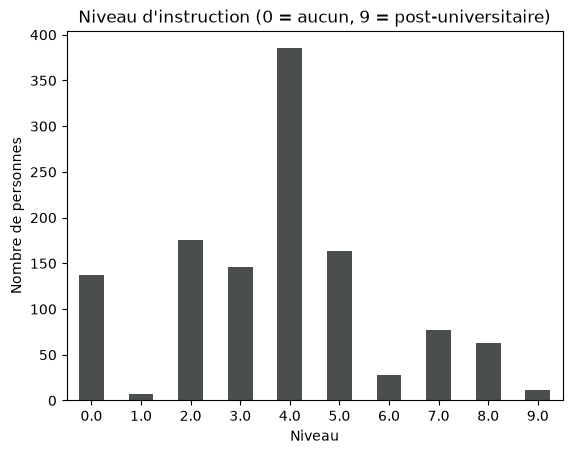

In [8]:
# Combien de personnes à chaque niveau d'instruction
donnees["niveau_instruction"].value_counts().sort_index().plot(kind="bar", color="#4A4F4D", rot=0)
plt.title("Niveau d'instruction (0 = aucun, 9 = post-universitaire)")
plt.xlabel("Niveau")
plt.ylabel("Nombre de personnes")
plt.show()

## Étape 6 · Les valeurs aberrantes

**La règle des quartiles (ou règle de Tukey)**, la plus utilisée pour repérer des valeurs aberrantes :
- Q1 = la valeur sous laquelle se trouvent 25 % des observations ; Q3 = celle sous laquelle se trouvent 75 % ;
- l'écart interquartile vaut Q3 − Q1 ;
- une valeur est dite **aberrante** si elle est en dessous de Q1 − 1,5 × écart ou au-dessus de Q3 + 1,5 × écart.

Attention : *aberrant* veut dire *inhabituel*, pas forcément *faux*. Chaque valeur repérée se discute avec la connaissance du terrain.

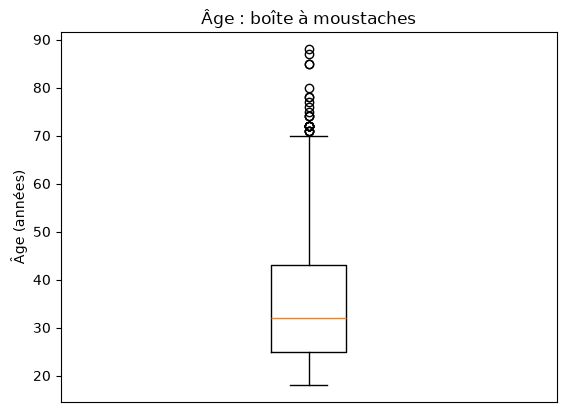

In [9]:
# La boîte à moustaches : la boîte va de Q1 à Q3, le trait central est la médiane, les points isolés sont les valeurs aberrantes
plt.boxplot(donnees["age"].dropna())
plt.xticks([])                          # pas d'étiquette sous la boîte
plt.title("Âge : boîte à moustaches")
plt.ylabel("Âge (années)")
plt.show()

In [10]:
q1 = donnees["age"].quantile(0.25)        # 25 % des personnes ont moins que cet âge
q3 = donnees["age"].quantile(0.75)        # 75 % des personnes ont moins que cet âge
ecart = q3 - q1                           # l'écart interquartile
limite_haute = q3 + 1.5 * ecart

print("Q1 =", q1, "  Q3 =", q3, "  limite haute =", limite_haute, "ans")

ages_aberrants = donnees[donnees["age"] > limite_haute]
print("Personnes au-dessus de la limite :", len(ages_aberrants))
ages_aberrants[["region", "milieu", "age", "sexe"]].sort_values("age").tail()

Q1 = 25.0   Q3 = 43.0   limite haute = 70.0 ans
Personnes au-dessus de la limite : 25


,region,milieu,age,sexe
324,Lomé Commune,urbain,80.0,femme
571,Centrale,rural,85.0,femme
1070,Lomé Commune,urbain,85.0,homme
1148,Maritime,rural,87.0,homme
733,Maritime,rural,88.0,homme


**Décision.** Ces personnes sont âgées, mais leur âge est tout à fait plausible : ce ne sont pas des erreurs. On les **garde**.
Retirer une valeur aberrante seulement parce qu'elle est rare reviendrait à effacer une partie de la population étudiée.

## Étape 7 · Ce que l'on veut expliquer : le manque de soins

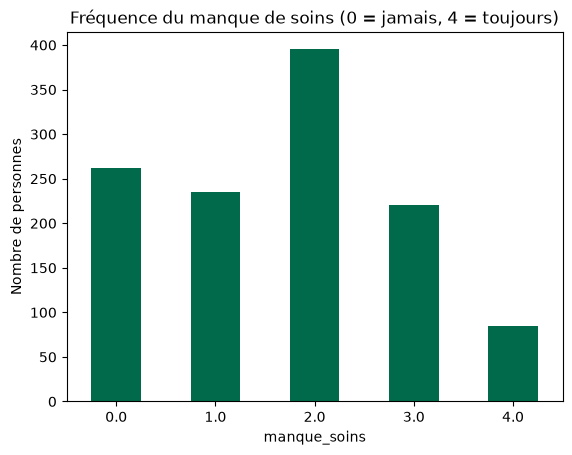

In [11]:
donnees["manque_soins"].value_counts().sort_index().plot(kind="bar", color="#006A4A", rot=0)
plt.title("Fréquence du manque de soins (0 = jamais, 4 = toujours)")
plt.ylabel("Nombre de personnes")
plt.show()

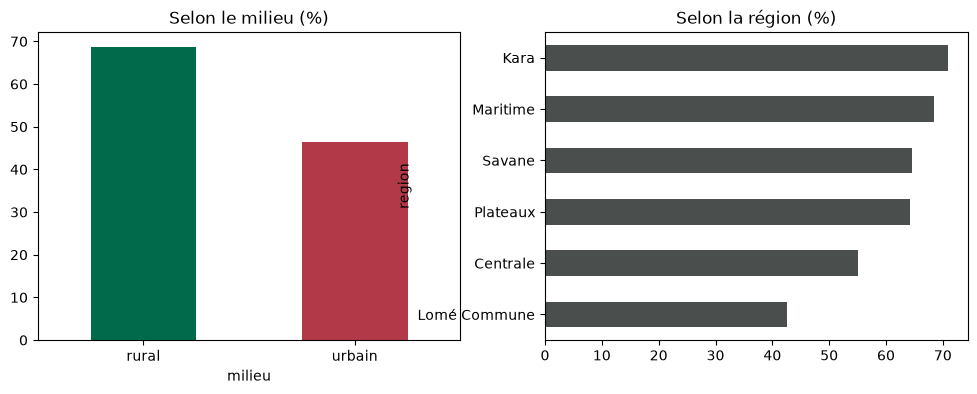

In [12]:
# Part des personnes ayant manqué de soins au moins « quelques fois », selon le milieu, puis selon la région
donnees["a_manque_de_soins"] = donnees["manque_soins"] >= 2

par_milieu = donnees.groupby("milieu")["a_manque_de_soins"].mean() * 100
par_region = donnees.groupby("region")["a_manque_de_soins"].mean().sort_values() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
par_milieu.plot(kind="bar", color=["#006A4A", "#B23A48"], rot=0, ax=axes[0])
axes[0].set_title("Selon le milieu (%)")
par_region.plot(kind="barh", color="#4A4F4D", ax=axes[1])
axes[1].set_title("Selon la région (%)")
plt.show()

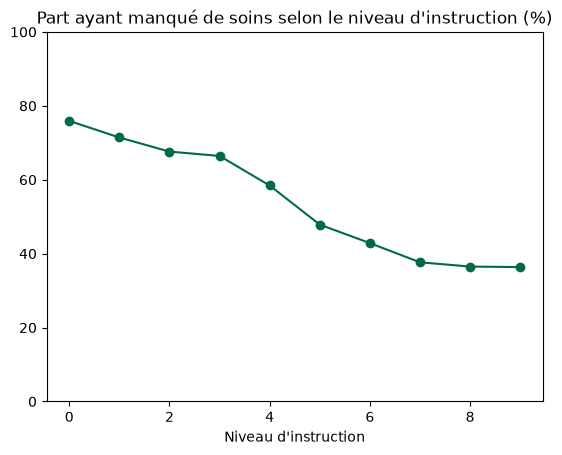

In [13]:
# Selon le niveau d'instruction
par_instruction = donnees.groupby("niveau_instruction")["a_manque_de_soins"].mean() * 100

par_instruction.plot(marker="o", color="#006A4A")
plt.title("Part ayant manqué de soins selon le niveau d'instruction (%)")
plt.xlabel("Niveau d'instruction")
plt.ylim(0, 100)
plt.show()

**Questions à discuter** : quelle région est la plus touchée ? L'écart entre Lomé et le reste du pays vous surprend-il ? Le manque de soins baisse-t-il régulièrement avec l'instruction ?

## Étape 8 · Les services présents dans les zones

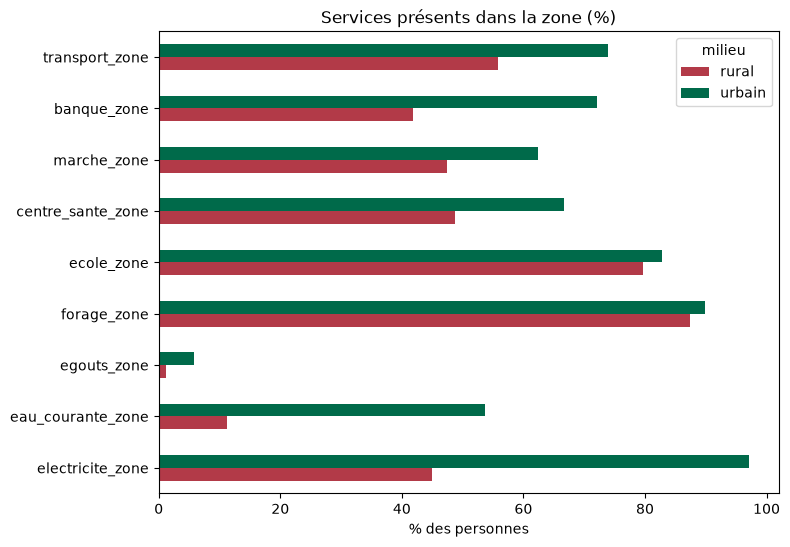

In [14]:
services = ["electricite_zone", "eau_courante_zone", "egouts_zone", "forage_zone", "ecole_zone",
            "centre_sante_zone", "marche_zone", "banque_zone", "transport_zone"]

# Part des personnes disposant de chaque service, en ville et à la campagne
presence = donnees.groupby("milieu")[services].mean().T * 100

presence.plot(kind="barh", color=["#B23A48", "#006A4A"], figsize=(8, 6))
plt.title("Services présents dans la zone (%)")
plt.xlabel("% des personnes")
plt.show()

## Étape 9 · Les liens entre variables : les corrélations

Une corrélation proche de 1 indique que deux variables augmentent ensemble ; proche de −1, que l'une baisse quand l'autre monte ; proche de 0, qu'il n'y a pas de lien linéaire.

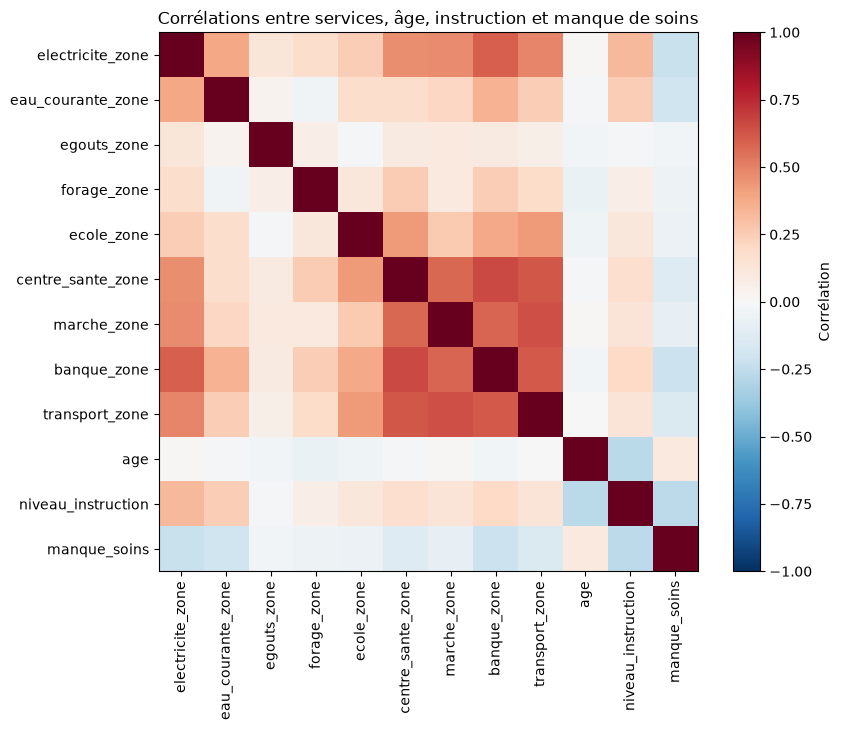

In [15]:
correlations = donnees[services + ["age", "niveau_instruction", "manque_soins"]].corr()      # corrélation entre chaque paire de colonnes (de -1 à 1)

plt.figure(figsize=(9, 7))
plt.imshow(correlations, cmap="RdBu_r", vmin=-1, vmax=1)    # rouge = varient ensemble, bleu = en sens contraire
plt.colorbar(label="Corrélation")
plt.xticks(range(len(correlations)), correlations.columns, rotation=90)
plt.yticks(range(len(correlations)), correlations.columns)
plt.title("Corrélations entre services, âge, instruction et manque de soins")
plt.show()

**À regarder** : les services vont souvent ensemble (là où il y a l'électricité, il y a souvent l'eau courante et une banque). Et la dernière ligne, `manque_soins`, est très pâle : aucune variable n'est fortement liée au manque de soins à elle seule. Le modèle aura du mal, et c'est une information.

# Partie B · Construire les modèles

## Étape 10 · Définir ce que l'on veut prédire

Une réponse **oui ou non** : la personne a-t-elle manqué de soins **au moins quelques fois** ? C'est une **classification**.

In [16]:
# 1 = a manqué de soins au moins quelques fois, 0 = jamais ou rarement
donnees["cible"] = (donnees["manque_soins"] >= 2).astype(int)
donnees["cible"].value_counts()

cible
1    700
0    500
Name: count, dtype: int64

## Étape 11 · Préparer les données

Le modèle ne comprend que des nombres : on transforme « urbain / rural » et « homme / femme » en 1 et 0, on choisit les colonnes utiles, puis on retire les personnes pour qui une information manque.

In [17]:
donnees["urbain"] = (donnees["milieu"] == "urbain").astype(int)
donnees["femme"] = (donnees["sexe"] == "femme").astype(int)

colonnes = ["urbain", "age", "femme", "niveau_instruction",
            "electricite_zone", "eau_courante_zone", "egouts_zone", "forage_zone",
            "ecole_zone", "centre_sante_zone", "marche_zone", "banque_zone", "transport_zone",
            "menage_radio", "menage_television", "menage_ordinateur", "menage_compte_bancaire"]

propres = donnees.dropna(subset=colonnes + ["manque_soins"])
print("Personnes conservées :", len(propres), "sur", len(donnees))

X = propres[colonnes]   # X : ce que le modèle regarde
y = propres["cible"]    # y : ce que le modèle doit trouver

Personnes conservées : 1072 sur 1200


## Étape 12 · Séparer apprentissage et test

On cache 30 % des personnes au modèle. Il apprend sur les 70 % restants, puis on vérifie s'il devine bien pour des personnes **jamais vues**.

In [18]:
X_apprentissage, X_test, y_apprentissage, y_test = train_test_split(
    X, y,
    test_size=0.3,      # 30 % des personnes mises de côté pour le test
    stratify=y,         # même proportion de « oui » dans les deux parties
    random_state=42)    # pour obtenir les mêmes résultats à chaque exécution

print("Apprentissage :", len(X_apprentissage), "personnes")
print("Test :", len(X_test), "personnes")

Apprentissage : 750 personnes
Test : 322 personnes


## Étape 13 · Un premier modèle simple : la régression logistique

In [19]:
modele_simple = LogisticRegression(max_iter=5000)
modele_simple.fit(X_apprentissage, y_apprentissage)          # il apprend

predictions_simple = modele_simple.predict(X_test)           # il devine pour les personnes du test
print("Bonnes réponses (régression logistique) :", round(accuracy_score(y_test, predictions_simple) * 100, 1), "%")

Bonnes réponses (régression logistique) : 68.9 %


## Étape 14 · Un modèle d'IA : la forêt aléatoire

Une forêt aléatoire combine plusieurs centaines d'arbres de décision. Chaque arbre pose une suite de questions (« la zone a-t-elle un centre de santé ? », « la personne a-t-elle plus de 50 ans ? »…), puis les arbres votent.

In [20]:
foret = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)   # 300 arbres
foret.fit(X_apprentissage, y_apprentissage)

predictions_foret = foret.predict(X_test)
print("Bonnes réponses (forêt aléatoire) :", round(accuracy_score(y_test, predictions_foret) * 100, 1), "%")

Bonnes réponses (forêt aléatoire) : 67.4 %


## Étape 15 · Comparer à une réponse « sans modèle »

Un taux de bonnes réponses ne veut rien dire seul. Comparons-le à quelqu'un qui répondrait **toujours la réponse la plus fréquente**.

In [21]:
reponse_la_plus_frequente = y_apprentissage.mode()[0]
toujours_la_meme = [reponse_la_plus_frequente] * len(y_test)
print("Bonnes réponses en répondant toujours la même chose :", round(accuracy_score(y_test, toujours_la_meme) * 100, 1), "%")

Bonnes réponses en répondant toujours la même chose : 59.0 %


# Partie C · Analyser les résultats

## Étape 16 · Le tableau des erreurs (matrice de confusion)

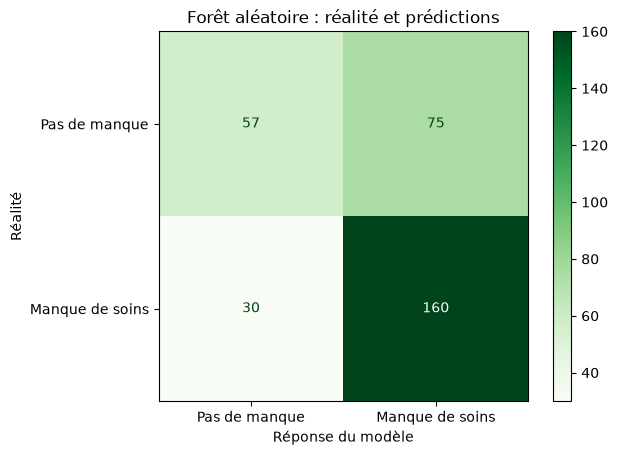

Personnes en manque de soins repérées : 84.2 %


In [22]:
ConfusionMatrixDisplay.from_predictions(y_test, predictions_foret, display_labels=["Pas de manque", "Manque de soins"], cmap="Greens")
plt.title("Forêt aléatoire : réalité et prédictions")
plt.xlabel("Réponse du modèle")
plt.ylabel("Réalité")
plt.show()

# Parmi les personnes qui ont réellement manqué de soins, combien le modèle en repère-t-il ?
print("Personnes en manque de soins repérées :", round(recall_score(y_test, predictions_foret) * 100, 1), "%")

**À lire** : la case en bas à droite compte les personnes en manque de soins bien repérées ; la case en haut à droite, les personnes signalées à tort. Le modèle signale beaucoup de monde : il « joue la prudence » parce que les personnes en manque de soins sont majoritaires.

## Étape 17 · Les probabilités données par le modèle

Avant de répondre oui ou non, la forêt calcule une **probabilité**. Regardons-les pour les deux groupes réels.

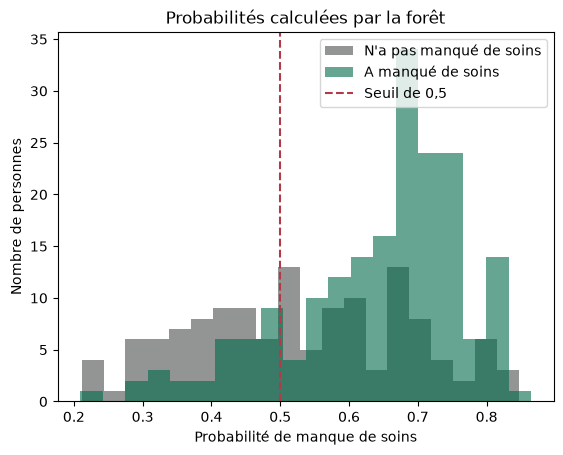

In [23]:
probabilites_test = foret.predict_proba(X_test)[:, 1]     # probabilité de « manque de soins » pour chaque personne du test

plt.hist(probabilites_test[y_test == 0], bins=20, alpha=0.6, color="#4A4F4D", label="N'a pas manqué de soins")
plt.hist(probabilites_test[y_test == 1], bins=20, alpha=0.6, color="#006A4A", label="A manqué de soins")
plt.axvline(0.5, color="#B23A48", linestyle="--", label="Seuil de 0,5")
plt.title("Probabilités calculées par la forêt")
plt.xlabel("Probabilité de manque de soins")
plt.ylabel("Nombre de personnes")
plt.legend()
plt.show()

Les deux histogrammes se chevauchent beaucoup : le modèle sépare mal les deux groupes. Un bon modèle produirait deux bosses bien distinctes.

## Étape 18 · Changer le seuil de décision

Par défaut, le modèle répond « oui » au-dessus de 0,5. Un chercheur ou un programme social peut préférer un autre seuil.

In [24]:
for seuil in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    reponses = (probabilites_test >= seuil).astype(int)
    print("Seuil", seuil,
          "| bonnes réponses :", round(accuracy_score(y_test, reponses) * 100, 1), "%",
          "| personnes en manque repérées :", round(recall_score(y_test, reponses) * 100, 1), "%",
          "| personnes signalées :", reponses.sum(), "sur", len(reponses))

Seuil 0.3 | bonnes réponses : 60.9 % | personnes en manque repérées : 98.4 % | personnes signalées : 310 sur 322
Seuil 0.4 | bonnes réponses : 65.8 % | personnes en manque repérées : 94.7 % | personnes signalées : 280 sur 322
Seuil 0.5 | bonnes réponses : 67.4 % | personnes en manque repérées : 84.2 % | personnes signalées : 235 sur 322
Seuil 0.6 | bonnes réponses : 67.7 % | personnes en manque repérées : 70.0 % | personnes signalées : 180 sur 322


Seuil 0.7 | bonnes réponses : 55.9 % | personnes en manque repérées : 36.3 % | personnes signalées : 90 sur 322
Seuil 0.8 | bonnes réponses : 44.4 % | personnes en manque repérées : 7.9 % | personnes signalées : 19 sur 322


**À discuter** : un seuil bas repère presque tout le monde, mais signale beaucoup de personnes à tort. Un seuil haut se trompe moins souvent quand il signale, mais en oublie beaucoup. Le bon seuil dépend de l'usage, pas de la statistique.

## Étape 19 · Le surapprentissage

Un modèle peut « apprendre par cœur » les données d'apprentissage. On le voit quand il réussit très bien sur ce qu'il a vu, et beaucoup moins bien sur ce qu'il n'a pas vu.

In [25]:
# min_samples_leaf : nombre minimal de personnes dans chaque « feuille » d'un arbre. Petit = arbres très détaillés.
for feuille in [1, 5, 20, 50]:
    essai = RandomForestClassifier(n_estimators=300, min_samples_leaf=feuille, random_state=42)
    essai.fit(X_apprentissage, y_apprentissage)
    sur_apprentissage = accuracy_score(y_apprentissage, essai.predict(X_apprentissage))
    sur_test = accuracy_score(y_test, essai.predict(X_test))
    print("Feuilles de", feuille, "| apprentissage :", round(sur_apprentissage * 100, 1), "%", "| test :", round(sur_test * 100, 1), "%")

Feuilles de 1 | apprentissage : 99.6 % | test : 67.1 %


Feuilles de 5 | apprentissage : 76.7 % | test : 67.4 %


Feuilles de 20 | apprentissage : 68.8 % | test : 68.0 %


Feuilles de 50 | apprentissage : 66.3 % | test : 66.8 %


Avec des feuilles d'une seule personne, la forêt réussit presque 100 % sur les données d'apprentissage… mais pas mieux sur le test : elle a appris par cœur. **Seul le score sur le test compte.**

## Étape 20 · La stabilité du résultat : la validation croisée

Le score dépend du découpage au hasard de l'étape 12. La validation croisée découpe les données en 5 parts et teste tour à tour sur chacune.

In [26]:
# 5 parts, en mélangeant d'abord les personnes (shuffle=True) et en gardant la même proportion de « oui » dans chaque part
decoupage = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores_logistique = cross_val_score(LogisticRegression(max_iter=5000), X, y, cv=decoupage)
scores_foret = cross_val_score(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42), X, y, cv=decoupage)

print("Régression logistique, 5 essais :", (scores_logistique * 100).round(1), "→ moyenne", round(scores_logistique.mean() * 100, 1), "%")
print("Forêt aléatoire, 5 essais :", (scores_foret * 100).round(1), "→ moyenne", round(scores_foret.mean() * 100, 1), "%")

Régression logistique, 5 essais : [64.7 64.2 64.5 65.9 66.4] → moyenne 65.1 %
Forêt aléatoire, 5 essais : [70.7 65.1 66.8 65.4 63.6] → moyenne 66.3 %


Le score varie de quelques points d'un découpage à l'autre : un écart de 1 ou 2 points entre deux modèles n'est donc pas significatif.

## Étape 21 · Ce qui compte pour le modèle

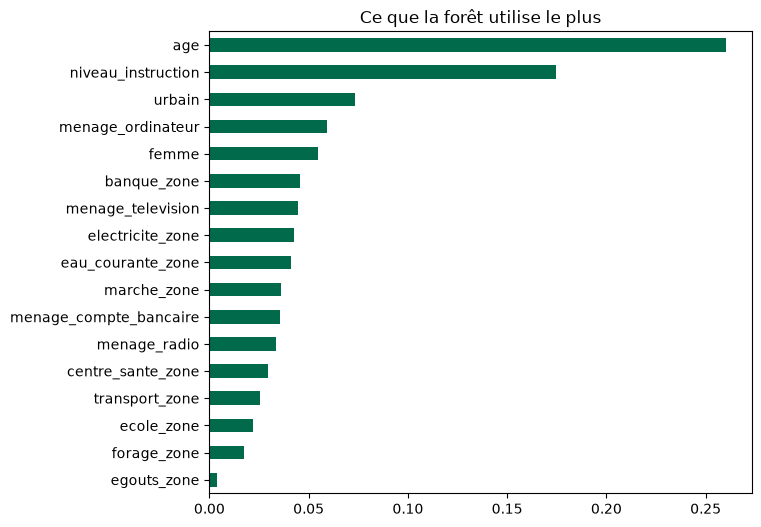

In [27]:
importance = pd.Series(foret.feature_importances_, index=colonnes).sort_values()

importance.plot(kind="barh", color="#006A4A", figsize=(7, 6))
plt.title("Ce que la forêt utilise le plus")
plt.show()

L'importance dit **ce que le modèle utilise**, pas ce qui **cause** le manque de soins. Les variables continues comme l'âge sont aussi favorisées par la méthode, car elles offrent plus de façons de découper.

## Étape 22 · Regarder les erreurs de près

Qui sont les personnes signalées à tort ? Comparons leur profil moyen à celui des personnes correctement repérées.

In [28]:
test = X_test.copy()
test["realite"] = y_test
test["prediction"] = predictions_foret

signalees_a_tort = test[(test["prediction"] == 1) & (test["realite"] == 0)]
bien_reperees = test[(test["prediction"] == 1) & (test["realite"] == 1)]

comparaison = pd.DataFrame({
    "Signalées à tort": signalees_a_tort[colonnes].mean(),
    "Bien repérées": bien_reperees[colonnes].mean()}).round(2)
comparaison

,Signalées à tort,Bien repérées
urbain,0.36,0.24
age,35.84,38.51
femme,0.53,0.53
niveau_instruction,3.15,2.96
electricite_zone,0.64,0.53
eau_courante_zone,0.23,0.15
egouts_zone,0.01,0.01
forage_zone,0.89,0.86
ecole_zone,0.81,0.79
centre_sante_zone,0.56,0.46


**À discuter** : les personnes signalées à tort ressemblent-elles aux autres ? Si oui, c'est qu'il manque au modèle une information qui les distinguerait (revenu, coût des soins, distance réelle…).

## Étape 23 · Et si l'on ajoute la région ?

La région est du texte. `get_dummies` crée une colonne 0/1 par région.

In [29]:
regions = pd.get_dummies(propres["region"], prefix="region", dtype=int)   # une colonne par région
X_avec_region = pd.concat([X, regions], axis=1)

scores_avec_region = cross_val_score(LogisticRegression(max_iter=5000), X_avec_region, y, cv=decoupage)
print("Sans la région :", round(scores_logistique.mean() * 100, 1), "%")
print("Avec la région :", round(scores_avec_region.mean() * 100, 1), "%")

Sans la région : 65.1 %
Avec la région : 66.0 %


Si le score ne bouge presque pas, la région n'apporte rien de plus que ce que disent déjà le milieu et les services : les écarts entre régions de l'étape 7 s'expliquent par ces autres variables.

# Partie D · Utiliser et conclure

## Étape 24 · Utiliser le prototype pour une nouvelle personne

In [30]:
# Une personne imaginaire : femme de 35 ans, milieu rural, primaire achevé, centre de santé et école dans la zone, pas d'eau courante
nouvelle_personne = pd.DataFrame([{
    "urbain": 0, "age": 35, "femme": 1, "niveau_instruction": 3,
    "electricite_zone": 1, "eau_courante_zone": 0, "egouts_zone": 0, "forage_zone": 1,
    "ecole_zone": 1, "centre_sante_zone": 1, "marche_zone": 1, "banque_zone": 0, "transport_zone": 1,
    "menage_radio": 1, "menage_television": 0, "menage_ordinateur": 0, "menage_compte_bancaire": 0}])

print("Probabilité estimée d'avoir manqué de soins :", round(foret.predict_proba(nouvelle_personne)[0][1] * 100), "%")

# La même personne, mais en ville
meme_personne_en_ville = nouvelle_personne.copy()
meme_personne_en_ville["urbain"] = 1
print("La même personne en milieu urbain :", round(foret.predict_proba(meme_personne_en_ville)[0][1] * 100), "%")

Probabilité estimée d'avoir manqué de soins : 67 %
La même personne en milieu urbain : 67 %


Si les deux probabilités sont proches, c'est que le milieu pèse peu une fois connus les services et les caractéristiques de la personne. Essayez de changer d'autres informations : l'âge, l'instruction, le centre de santé.

## Étape 25 · Limites

- 1 200 personnes interrogées en une seule fois : on observe des liens, pas des causes.
- Les services sont notés « présents dans la zone », sans distance, coût ni qualité.
- Le modèle fait mieux que le hasard, mais de peu : les services présents ne suffisent pas à expliquer le manque de soins. C'est un résultat en soi.
- Ce prototype sert à la recherche, jamais à décider de l'aide à apporter à une personne.

## Étape 26 · À vous

1. À l'étape 10, changez la définition de la cible : `>= 3` (au moins « plusieurs fois ») au lieu de `>= 2`. Les résultats changent-ils ?
2. À l'étape 11, retirez l'âge des colonnes. Que devient le score ? Quelle variable devient la plus importante ?
3. Refaites l'étape 7 pour les femmes seulement : `donnees[donnees["sexe"] == "femme"]`.
4. **Et pour votre sujet ?** Remplacez le fichier par votre propre enquête : une ligne par personne ou par ménage, une colonne oui / non à prédire, des colonnes explicatives. Les étapes 3 à 24 restent les mêmes.